In [ ]:
import pandas as pd 
import numpy as np
df = pd.read_csv('E:\\Used-Car-Price-Prediction\\data\\raw\\CAR DETAILS FROM CAR DEKHO.csv')
df.head() # prints first 5 rows 

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [ ]:
print("Shape : ",df.shape) # shape of the dataset
print("\nColumns Names") 
df.columns.to_list() # coloumns into list

Shape :  (4340, 8)

Columns Names


['name',
 'year',
 'selling_price',
 'km_driven',
 'fuel',
 'seller_type',
 'transmission',
 'owner']

In [ ]:
df.info() # tells about null values and data types of the coloumns

<class 'pandas.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           4340 non-null   str  
 1   year           4340 non-null   int64
 2   selling_price  4340 non-null   int64
 3   km_driven      4340 non-null   int64
 4   fuel           4340 non-null   str  
 5   seller_type    4340 non-null   str  
 6   transmission   4340 non-null   str  
 7   owner          4340 non-null   str  
dtypes: int64(3), str(5)
memory usage: 271.4 KB


In [ ]:
df.describe() # coloumns ka Statistical summary

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


# Check missing value

In [5]:
df.isnull().sum() # sum of null values in every coloumn

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

In [6]:
df.duplicated().sum() # sum of duplicated rows 

np.int64(763)

In [7]:
df.shape

(4340, 8)

In [9]:
df = df.drop_duplicates() # remove duplicates
print("Shape after removing duplicates :",df.shape) 

Shape after removing duplicates : (3577, 8)


# Analyze Fuel, owner , Transmission , Seller type

In [10]:
print("Fuel Type :",df['fuel'].value_counts()) # fuel type and their counts
print("\nOwner :",df["owner"].value_counts())
print("\nTransmission :",df["transmission"].value_counts())
print("\nSeller type :",df["seller_type"].value_counts())

Fuel Type : fuel
Diesel      1800
Petrol      1717
CNG           37
LPG           22
Electric       1
Name: count, dtype: int64

Owner : owner
First Owner             2218
Second Owner             978
Third Owner              289
Fourth & Above Owner      75
Test Drive Car            17
Name: count, dtype: int64

Transmission : transmission
Manual       3265
Automatic     312
Name: count, dtype: int64

Seller type : seller_type
Individual          2832
Dealer               712
Trustmark Dealer      33
Name: count, dtype: int64


# Histogram Analysis

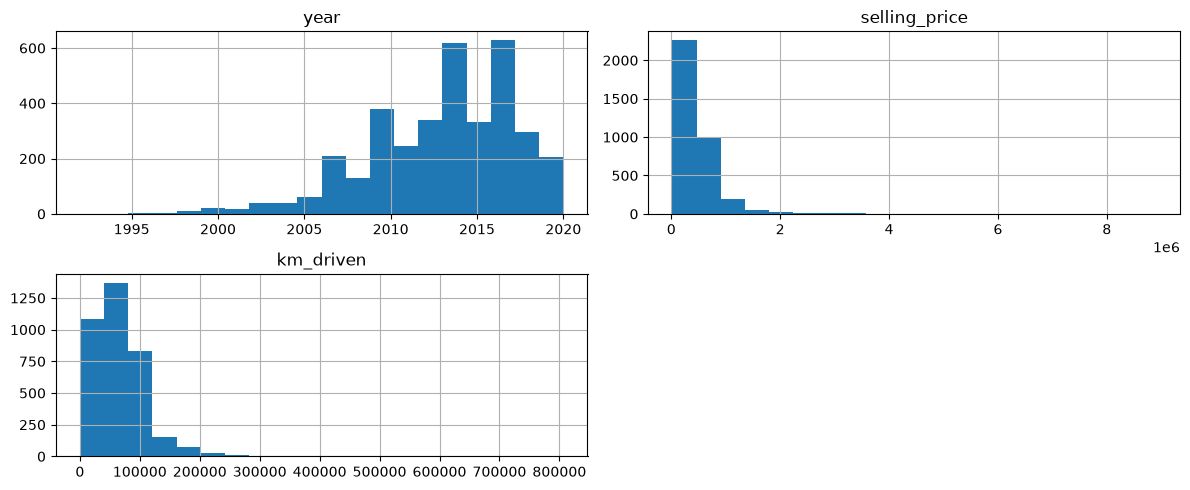

In [11]:
import matplotlib.pyplot as plt

df[['year', 'selling_price', 'km_driven']].hist(
    figsize=(12, 5),
    bins=20
)

plt.tight_layout()
plt.show()

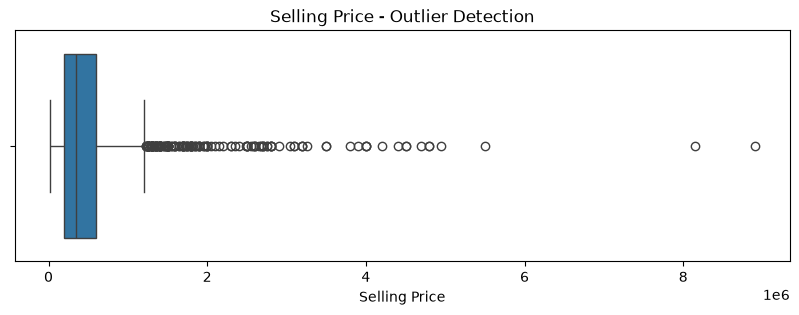

In [13]:
import seaborn as sns

plt.figure(figsize=(10, 3))

sns.boxplot(x=df['selling_price'])

plt.title("Selling Price - Outlier Detection")
plt.xlabel("Selling Price")

plt.show()

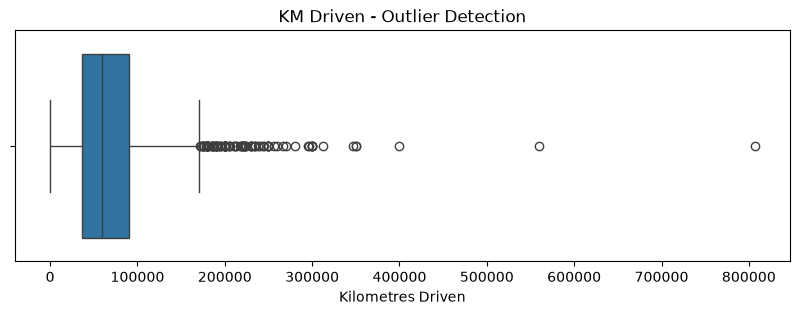

In [14]:
plt.figure(figsize=(10, 3))

sns.boxplot(x=df['km_driven'])

plt.title("KM Driven - Outlier Detection")
plt.xlabel("Kilometres Driven")

plt.show()

# IQR and Outliers Detection in selling price

In [15]:
Q1 = df['selling_price'].quantile(0.25)
Q3 = df['selling_price'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 200000.0
Q3: 600000.0
IQR: 400000.0
Lower Limit: -400000.0
Upper Limit: 1200000.0


In [ ]:
# We have to identify outliers
outliers = df[df['selling_price'] > upper_limit]  # upper limit se jyada selling price batayega 

print("Total Outliers:", len(outliers)) # Total elements in outlier variable

print("Percentage of Outliers:",
      (len(outliers) / len(df)) * 100) # total elements in outlier /total elements in dataframe 

Total Outliers: 170
Percentage of Outliers: 4.752585965893206


# top 10 entries from Outlier variable

In [17]:
outliers[['name', 'year', 'selling_price', 'km_driven']].head(10)

,name,year,selling_price,km_driven
12,Toyota Corolla Altis 1.8 VL CVT,2018,1650000,25000
29,Jaguar XF 2.2 Litre Luxury,2014,1964999,28000
30,Mercedes-Benz New C-Class 220 CDI AT,2013,1425000,59000
35,Audi A6 2.0 TDI Design Edition,2013,1735000,50000
36,Mercedes-Benz New C-Class C 220 CDI Avantgarde,2012,1375000,33800
39,Toyota Innova 2.5 G (Diesel) 7 Seater,2015,1300000,80000
40,Jeep Compass 1.4 Sport Plus BSIV,2019,1400000,10000
43,BMW 3 Series 320d Sport Line,2013,1550000,75800
44,Audi Q7 35 TDI Quattro Premium,2009,1250000,78000
89,Mercedes-Benz S-Class S 350d Connoisseurs Edition,2017,8150000,6500


# Outliers in km_Driven

In [21]:
Q1_km = df['km_driven'].quantile(0.25)
Q3_km = df['km_driven'].quantile(0.75)

IQR_km = Q3_km - Q1_km

lower_km = Q1_km - 1.5 * IQR_km
upper_km = Q3_km + 1.5 * IQR_km

km_outliers = df[df['km_driven'] > upper_km]

print("Lower Limit:", lower_km)
print("Upper Limit:", upper_km)
print("Total KM Outliers:", len(km_outliers))

Lower Limit: -45000.0
Upper Limit: 171000.0
Total KM Outliers: 106


In [19]:
km_outliers[['name', 'year', 'km_driven', 'selling_price']].head(10)

,name,year,km_driven,selling_price
32,Audi Q5 2.0 TDI,2011,175900,1190000
69,Chevrolet Tavera Neo LS B3 - 7(C) seats BSIII,2010,350000,280000
70,Toyota Corolla Altis Diesel D4DG,2011,230000,350000
159,Chevrolet Enjoy 1.3 TCDi LS 8,2015,175000,300000
197,Mahindra Xylo E4,2009,230000,229999
225,Mahindra Renault Logan 1.5 DLS,2008,213000,89999
269,Maruti Alto LXi,2007,195000,100000
306,Mahindra Bolero Power Plus Plus AC BSIV PS,2015,200000,430000
324,Mahindra XUV500 W8 2WD,2012,212814,850000
344,Mahindra Bolero SLX,2006,200000,229999


# we check model years 

In [22]:
print("Minimum Year:", df['year'].min())
print("Maximum Year:", df['year'].max())

print("\nYear Value Counts:")
print(df['year'].value_counts().sort_index())

Minimum Year: 1992
Maximum Year: 2020

Year Value Counts:
year
1992      1
1995      1
1996      2
1997      3
1998      9
1999      9
2000     12
2001     16
2002     18
2003     22
2004     38
2005     61
2006     93
2007    117
2008    129
2009    169
2010    210
2011    247
2012    338
2013    298
2014    321
2015    332
2016    283
2017    346
2018    295
2019    162
2020     45
Name: count, dtype: int64


# Scatterplot for km_driven vs selling price 

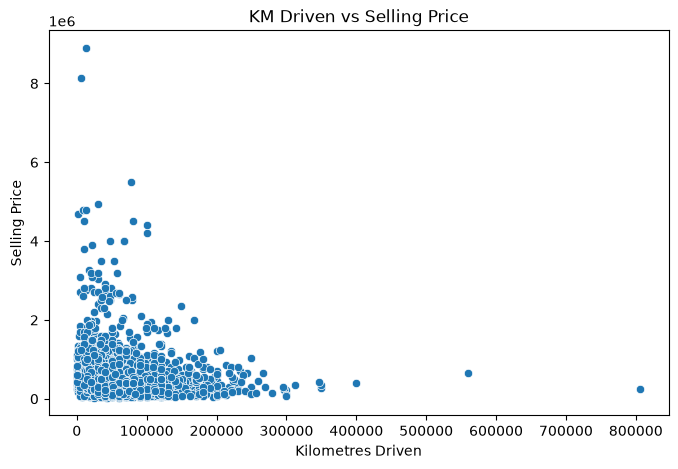

In [23]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='km_driven',
    y='selling_price'
)

plt.title("KM Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price")

plt.show()

# Correlation b/w km_driven and selling price

In [24]:
correlation = df['km_driven'].corr(df['selling_price'])

print("Correlation:", correlation)

Correlation: -0.18735891936683916


# heatmap

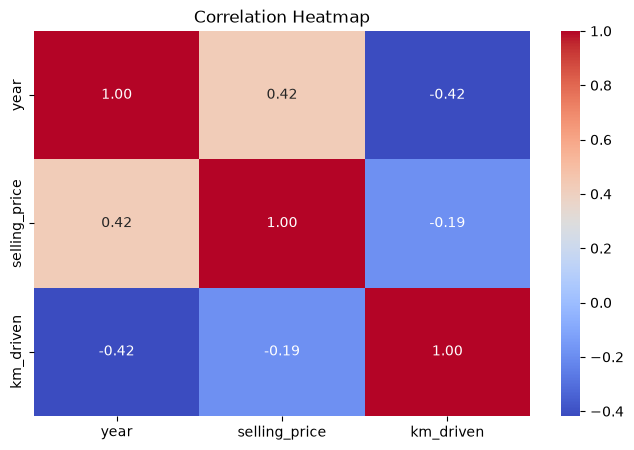

In [25]:
plt.figure(figsize=(8, 5))

correlation_matrix = df[
    ['year', 'selling_price', 'km_driven']
].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

# Brand Analysis

In [29]:
print("Unique Car Names:", df['name'].nunique())

print("\nSample Car Names:")
print(df['name'].head(10)) 

Unique Car Names: 1491

Sample Car Names:
0                Maruti 800 AC
1     Maruti Wagon R LXI Minor
2         Hyundai Verna 1.6 SX
3       Datsun RediGO T Option
4        Honda Amaze VX i-DTEC
5         Maruti Alto LX BSIII
6    Hyundai Xcent 1.2 Kappa S
7     Tata Indigo Grand Petrol
8     Hyundai Creta 1.6 VTVT S
9     Maruti Celerio Green VXI
Name: name, dtype: str


In [30]:
df['brand'] = df['name'].str.split().str[0]

print("Unique Brands:", df['brand'].nunique())

print("\nBrand Counts:")
print(df['brand'].value_counts())

Unique Brands: 29

Brand Counts:
brand
Maruti           1072
Hyundai           637
Mahindra          328
Tata              308
Ford              220
Honda             216
Toyota            170
Chevrolet         151
Renault           110
Volkswagen         93
Nissan             52
Skoda              49
Fiat               32
Audi               31
Datsun             29
BMW                25
Mercedes-Benz      21
Jaguar              5
Mitsubishi          5
Land                5
Volvo               4
Jeep                3
Ambassador          3
MG                  2
OpelCorsa           2
Daewoo              1
Force               1
Isuzu               1
Kia                 1
Name: count, dtype: int64


In [31]:
print(df[['name', 'brand']].head(10))

                        name    brand
0              Maruti 800 AC   Maruti
1   Maruti Wagon R LXI Minor   Maruti
2       Hyundai Verna 1.6 SX  Hyundai
3     Datsun RediGO T Option   Datsun
4      Honda Amaze VX i-DTEC    Honda
5       Maruti Alto LX BSIII   Maruti
6  Hyundai Xcent 1.2 Kappa S  Hyundai
7   Tata Indigo Grand Petrol     Tata
8   Hyundai Creta 1.6 VTVT S  Hyundai
9   Maruti Celerio Green VXI   Maruti


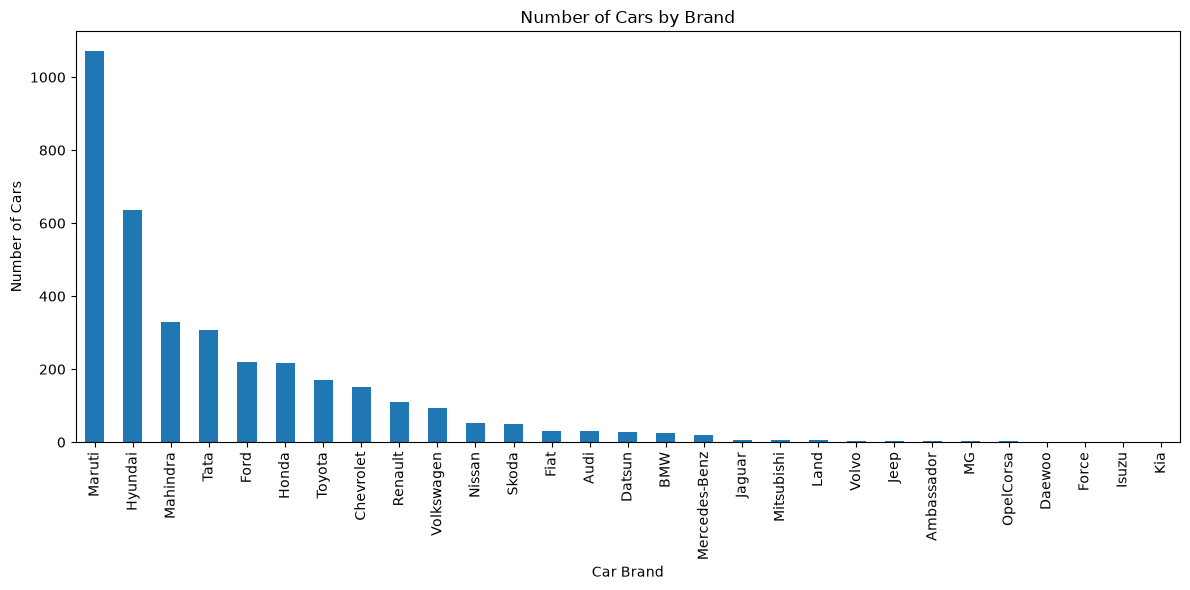

In [32]:
plt.figure(figsize=(12, 6))

df['brand'].value_counts().plot(kind='bar')

plt.title("Number of Cars by Brand")
plt.xlabel("Car Brand")
plt.ylabel("Number of Cars")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

# Average sales by their features (coloumn)

In [33]:
brand_price = df.groupby('brand')['selling_price'].mean()

brand_price = brand_price.sort_values(ascending=False)

print(brand_price)

brand
Land             3.609800e+06
Volvo            2.556250e+06
Mercedes-Benz    2.299238e+06
BMW              2.242800e+06
Audi             2.185452e+06
Jaguar           2.073000e+06
MG               1.842500e+06
Jeep             1.530000e+06
Isuzu            1.500000e+06
Kia              1.300000e+06
Mitsubishi       8.430000e+05
Toyota           8.389176e+05
Mahindra         5.847804e+05
Ford             5.636272e+05
Honda            5.399444e+05
Skoda            4.755510e+05
Volkswagen       4.616666e+05
Nissan           4.570384e+05
Hyundai          4.133406e+05
Renault          4.084000e+05
Force            3.460000e+05
Maruti           3.320312e+05
Datsun           2.965517e+05
Fiat             2.870937e+05
Tata             2.786724e+05
Chevrolet        2.327132e+05
Ambassador       2.000000e+05
OpelCorsa        8.850000e+04
Daewoo           6.000000e+04
Name: selling_price, dtype: float64


In [36]:

year_price = df.groupby('year')['selling_price'].mean()

print(year_price)

year
1992     50000.000000
1995     95000.000000
1996    225000.000000
1997     93000.000000
1998    165111.111111
1999     73888.888889
2000     81500.000000
2001    109562.437500
2002     86111.111111
2003     87090.909091
2004    126697.342105
2005    114821.442623
2006    154182.763441
2007    165282.042735
2008    177668.170543
2009    235467.420118
2010    275584.204762
2011    296028.291498
2012    379352.026627
2013    433046.285235
2014    512850.420561
2015    510051.159639
2016    638342.706714
2017    741184.927746
2018    820420.305085
2019    865364.166667
2020    804844.400000
Name: selling_price, dtype: float64


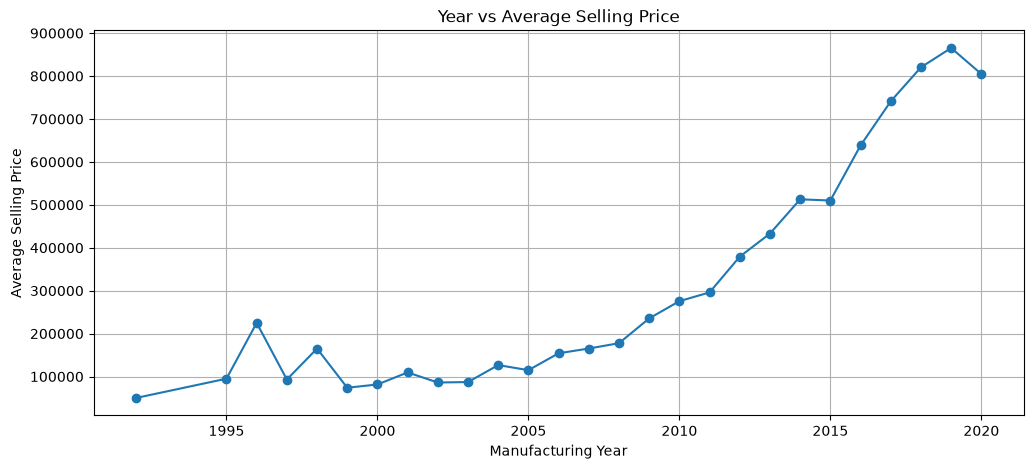

In [37]:
plt.figure(figsize=(12, 5))

year_price.plot(kind='line', marker='o')

plt.title("Year vs Average Selling Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Average Selling Price")

plt.grid()
plt.show()

In [38]:
fuel_price = df.groupby('fuel')['selling_price'].mean()

print(fuel_price.sort_values(ascending=False))

fuel
Diesel      614001.075000
Petrol      335344.340128
Electric    310000.000000
CNG         273162.081081
LPG         171818.136364
Name: selling_price, dtype: float64


In [39]:
transmission_price = df.groupby('transmission')['selling_price'].mean()

print(transmission_price)

transmission
Automatic    1.274955e+06
Manual       3.973657e+05
Name: selling_price, dtype: float64


In [40]:
owner_price = df.groupby('owner')['selling_price'].mean()

print(owner_price.sort_values(ascending=False))

owner
Test Drive Car          954293.941176
First Owner             565385.447250
Second Owner            341954.140082
Third Owner             266142.207612
Fourth & Above Owner    181213.293333
Name: selling_price, dtype: float64


In [41]:
seller_price = df.groupby('seller_type')['selling_price'].mean()

print(seller_price.sort_values(ascending=False))

seller_type
Trustmark Dealer    822272.727273
Dealer              652699.390449
Individual          424904.024364
Name: selling_price, dtype: float64


# EDA - Key Findings and Observations

## 1. Data Cleaning
- Original records: 4340
- Duplicate records found: 763
- Final records after removing duplicates: 3577
- No missing values found.

## 2. Numerical Analysis
- Manufacturing year range: 1992 to 2020.
- Year vs Selling Price correlation: +0.42
- KM Driven vs Selling Price correlation: -0.19
- Year vs KM Driven correlation: -0.42

## 3. Outlier Analysis
- Selling Price outliers: 170 (4.75%)
- KM Driven outliers: 106 (2.96%)
- Outliers were identified but not removed.

## 4. Brand Analysis
- Total unique car names: 1491
- Total extracted brands: 29
- Maruti and Hyundai have the highest number of records.
- Land Rover has the highest average selling price.

## 5. Categorical Analysis
- Diesel has the highest average selling price among fuel types.
- Automatic cars have a higher average selling price than manual cars.
- Test Drive Cars have the highest average price among owner categories.
- Trustmark Dealers have the highest average price among seller types.

## 6. Conclusion
EDA helped us understand the dataset, identify outliers,
and discover relationships between car features and selling price.